In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy import interpolate
from scipy.optimize import minimize

In [3]:
def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

@jit(nopython=True)
def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

@jit(nopython=True)
def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2

In [17]:
# Initial Values :
g_quark = 2.5
n_quark = np.linspace(0.5344,1,20)
p = 63.177
e = 318.26 + 253.89

n_had =np.linspace(0.16,0.32,20)
Gam_had = 4.921
m0_had = 939.56
K_had = 17906.60 

In [18]:
K_quark = p / (n_quark[0] ** g_quark)
m0_quark = (e - (K_quark * (n_quark[0] ** g_quark)) / (g_quark - 1)) / n_quark[0]

# Hadronic EOS
p_had = P_from_nb(n_had, K_had, Gam_had)
mu_had = mu_from_nb(n_had, K_had, Gam_had, m0_had)

# Quark EOS
p_quark = P_from_nb(n_quark, K_quark, g_quark)
mu_quark = mu_from_nb(n_quark, K_quark, g_quark, m0_quark)
e_quark = e_from_n(n_quark, K_quark, g_quark, m0_quark)

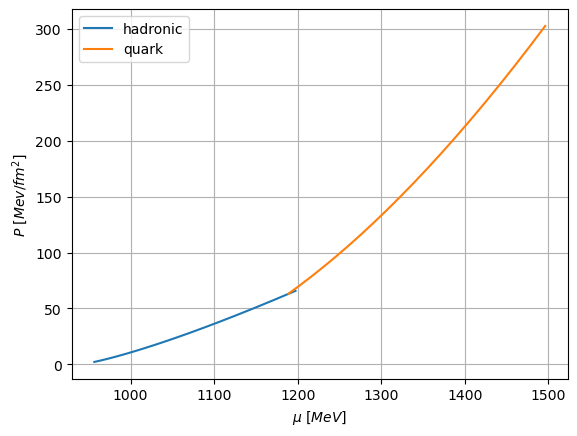

In [19]:
plt.plot(mu_had, p_had, label = "hadronic")
plt.plot(mu_quark, p_quark, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()